In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

In [2]:
import numpy as np
import pylab as plt
import glob
import os

import scipy.signal as sig
from pprint import pprint
import icewave.display.graphes as graphes

In [38]:
from dji_thermal_sdk.dji_sdk import *
from dji_thermal_sdk.utility import rjpeg_to_heatmap, rjpeg_to_thermal
import dji_thermal_sdk.dji_sdk as DJI
import ctypes as CT
from ctypes import *
import os
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

In [39]:
nbdev.show_doc(dji_init)

NameError: name 'nbdev' is not defined

In [128]:
from PIL import Image
from PIL.ExifTags import TAGS

import matplotlib.pyplot as plt
import numpy as np

global folder
folder = '/Users/stephane/Documents/BicWin2026/Data_Exemples/IR_0211/'

savefolder =  '/Users/stephane/Documents/BicWin2026/Data_Exemples/Results/'

if not os.path.exists(savefolder):
    os.makedirs(savefolder)
# path to the image or video
filelist = glob.glob(folder+'*_T.JPG')
pprint(len(filelist))
#imagename = folder + "DJI_20260212054323_0043_T.jpg"

imagename = filelist[50]
print(imagename)

# read the image data using PIL
im = plt.imread(imagename)

209
/Users/stephane/Documents/BicWin2026/Data_Exemples/IR_0211/DJI_20260212055706_0201_T.JPG


In [180]:
import icewave.drone.thermal as th

exif = th.get_exif(imagename,display=True)
data = th.read_rawdata(exif)



Dict: SourceFile = /Users/stephane/Documents/BicWin2026/Data_Exemples/IR_0211/DJI_20260212055706_0201_T.JPG
Dict: ExifTool:ExifToolVersion = 13.59
Dict: ExifTool:Warning = [minor] Possibly incorrect maker notes offsets (fix by -436?)
Dict: File:FileName = DJI_20260212055706_0201_T.JPG
Dict: File:Directory = /Users/stephane/Documents/BicWin2026/Data_Exemples/IR_0211
Dict: File:FileSize = 1810432
Dict: File:FileModifyDate = 2026:06:21 23:18:21+02:00
Dict: File:FileAccessDate = 2026:06:22 12:20:43+02:00
Dict: File:FileInodeChangeDate = 2026:06:21 23:18:21+02:00
Dict: File:FilePermissions = 100755
Dict: File:FileType = JPEG
Dict: File:FileTypeExtension = JPG
Dict: File:MIMEType = image/jpeg
Dict: File:ExifByteOrder = II
Dict: File:ImageWidth = 1280
Dict: File:ImageHeight = 1024
Dict: File:EncodingProcess = 0
Dict: File:BitsPerSample = 8
Dict: File:ColorComponents = 3
Dict: File:YCbCrSubSampling = 2 2
Dict: EXIF:ImageDescription = HotIron
Dict: EXIF:Make = DJI
Dict: EXIF:Model = M4T
Dict: E

In [ ]:
sc = plt.pcolormesh(data)
cbar = plt.colorbar(sc)

In [129]:
from PIL import Image, ExifTags
img = Image.open(imagename)a
exif = { ExifTags.TAGS[k]: v for k, v in img._getexif().items() if k in ExifTags.TAGS }
pprint(exif)

{'ApertureValue': 0.0,
 'BodySerialNumber': '1581F7K3C254W00D2JB8',
 'ColorSpace': 1,
 'ComponentsConfiguration': b'\x01\x02\x03\x00',
 'Contrast': 0,
 'CustomRendered': 0,
 'DateTime': '2026:02:12 05:57:06',
 'DateTimeDigitized': '2026:02:12 05:57:06',
 'DateTimeOriginal': '2026:02:12 05:57:06',
 'DeviceSettingDescription': b'\x00\x00\x00\x00',
 'DigitalZoomRatio': 1.0,
 'ExifImageHeight': 1024,
 'ExifImageWidth': 1280,
 'ExifInteroperabilityOffset': 716,
 'ExifOffset': 260,
 'ExifVersion': b'0230',
 'FNumber': 1.0,
 'FileSource': b'\x03',
 'Flash': 0,
 'FlashPixVersion': b'0100',
 'FocalLength': 12.0,
 'FocalLengthIn35mmFilm': 52,
 'GPSInfo': {0: b'\x02\x03\x00\x00',
             1: 'N',
             2: (48.0, 20.0, 10.7298),
             3: 'W',
             4: (68.0, 50.0, 52.7943),
             5: b'\x00',
             6: 87.305,
             9: 'A',
             18: 'WGS-84\x00'},
 'ImageDescription': 'HotIron',
 'LensSpecification': (12.0, 12.0, 1.0, 1.0),
 'Make': 'DJI',
 'Make

In [130]:
from exiftool import ExifToolHelper

exifs = {}
with ExifToolHelper() as et:
    for d in et.get_metadata(imagename,params = '-b'):
        for k, v in d.items():
            print(f"Dict: {k} = {v}")
            exifs[k] = v

Dict: SourceFile = /Users/stephane/Documents/BicWin2026/Data_Exemples/IR_0211/DJI_20260212055706_0201_T.JPG
Dict: ExifTool:ExifToolVersion = 13.59
Dict: ExifTool:Warning = [minor] Possibly incorrect maker notes offsets (fix by -436?)
Dict: File:FileName = DJI_20260212055706_0201_T.JPG
Dict: File:Directory = /Users/stephane/Documents/BicWin2026/Data_Exemples/IR_0211
Dict: File:FileSize = 1810432
Dict: File:FileModifyDate = 2026:06:21 23:18:21+02:00
Dict: File:FileAccessDate = 2026:06:22 12:20:43+02:00
Dict: File:FileInodeChangeDate = 2026:06:21 23:18:21+02:00
Dict: File:FilePermissions = 100755
Dict: File:FileType = JPEG
Dict: File:FileTypeExtension = JPG
Dict: File:MIMEType = image/jpeg
Dict: File:ExifByteOrder = II
Dict: File:ImageWidth = 1280
Dict: File:ImageHeight = 1024
Dict: File:EncodingProcess = 0
Dict: File:BitsPerSample = 8
Dict: File:ColorComponents = 3
Dict: File:YCbCrSubSampling = 2 2
Dict: EXIF:ImageDescription = HotIron
Dict: EXIF:Make = DJI
Dict: EXIF:Model = M4T
Dict: E

In [131]:
pprint(list(exifs.keys()))

['SourceFile',
 'ExifTool:ExifToolVersion',
 'ExifTool:Warning',
 'File:FileName',
 'File:Directory',
 'File:FileSize',
 'File:FileModifyDate',
 'File:FileAccessDate',
 'File:FileInodeChangeDate',
 'File:FilePermissions',
 'File:FileType',
 'File:FileTypeExtension',
 'File:MIMEType',
 'File:ExifByteOrder',
 'File:ImageWidth',
 'File:ImageHeight',
 'File:EncodingProcess',
 'File:BitsPerSample',
 'File:ColorComponents',
 'File:YCbCrSubSampling',
 'EXIF:ImageDescription',
 'EXIF:Make',
 'EXIF:Model',
 'EXIF:Orientation',
 'EXIF:XResolution',
 'EXIF:YResolution',
 'EXIF:ResolutionUnit',
 'EXIF:Software',
 'EXIF:ModifyDate',
 'EXIF:YCbCrPositioning',
 'EXIF:FNumber',
 'EXIF:ExifVersion',
 'EXIF:DateTimeOriginal',
 'EXIF:CreateDate',
 'EXIF:ComponentsConfiguration',
 'EXIF:ApertureValue',
 'EXIF:MaxApertureValue',
 'EXIF:SubjectDistance',
 'EXIF:Flash',
 'EXIF:FocalLength',
 'EXIF:FlashpixVersion',
 'EXIF:ColorSpace',
 'EXIF:ExifImageWidth',
 'EXIF:ExifImageHeight',
 'EXIF:InteropIndex',
 'E

640

In [175]:
import base64

# Ta chaîne Base64
base64_str = exifs['APP3:ThermalData']
# Extraire la partie après "base64:"
if base64_str.startswith("base64:"):
    base64_str = base64_str[7:]  # Enleve "base64:"
# Décoder en bytes
binary_data = base64.b64decode(base64_str)
print(f"Taille des données binaires : {len(binary_data)} octets")

# Convertir en numpy array
uint16_array_np = np.frombuffer(binary_data, dtype=np.uint16)

print(len(uint16_array_np))

# Récupère les dimensions réelles du capteur
nx = int(exifs['File:ImageHeight']/2)
ny = int(exifs['File:ImageWidth']/2)

# Conversion en image
data = np.reshape(uint16_array_np,(nx,ny))

#binary_data

Taille des données binaires : 655360 octets
327680


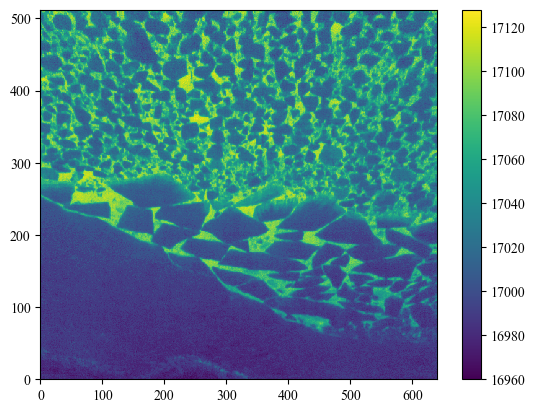

42.0


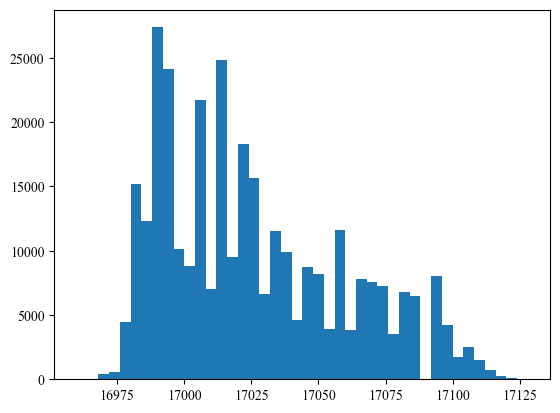

In [168]:

xmin = np.min(np.ndarray.flatten(data))
xmax = np.max(np.ndarray.flatten(data))

N = (xmax-xmin)
print(N/4)
n = plt.hist(np.ndarray.flatten(data),range=[xmin,xmax],bins=int(N/4))

In [147]:
data

array([[16996, 16988, 16980, ..., 16984, 16984, 16976],
       [16980, 16984, 16984, ..., 16988, 16992, 16980],
       [16988, 16980, 16984, ..., 16988, 16988, 16980],
       ...,
       [17032, 17040, 17040, ..., 17092, 17092, 17084],
       [17036, 17064, 17060, ..., 17104, 17100, 17104],
       [17044, 17056, 17068, ..., 17084, 17096, 17092]],
      shape=(512, 640), dtype=uint16)

In [140]:
exifs['JFIF:ResolutionUnit']

0

In [141]:
2**16

65536

In [138]:
import base64

# Ta chaîne Base64 (exemple tronqué pour l'exemple)
base64_str = exifs['APP5:ThermalCalibration']
# Extraire la partie après "base64:"
if base64_str.startswith("base64:"):
    base64_str = base64_str[7:]  # Enlever "base64:"
print(base64_str[-40:])
# Décoder en bytes
binary_data = base64.b64decode(base64_str)
print(f"Taille des données binaires : {len(binary_data)} octets")

#binary_data
uint16_array_np = np.frombuffer(binary_data, dtype=np.uint16)

print(len(uint16_array_np))
print(uint16_array_np[:20])


#sc = plt.pcolormesh(data)
#plt.colorbar(sc)


cBlwGXAZcBlwGXAZcBlwGXAZcBlwGXAZcBlwGQ==
Taille des données binaires : 8176 octets
4088
[    1   302 65535 65535     1     3     1     2     0     0     1     1
 65535 65535 65535 65535 65535 65535 65535 65535]


In [139]:
 exifs['APP5:ThermalCalibration']

'base64:AQAuAf////8BAAMAAQACAAAAAAABAAEA/////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////wBAeD8cP8s+gT49Pv49xT2OPVs9Kz39PNE8qTyBPFo8NTwSPPA7zzuQO1U7HTvnOrQ6hDpWOik61TmFOTs59ji0OHU4ODj/N8g3iTcQN5s2Kja8NVA15zSBNBs0VzOYMoMyazI/MoExsjDTL+Iu6y0mLWostysMK3spCii0JnQlKCMUISsfZR28G7wbvBu8G7wbvBu8G7wbvBu8G7wbvBu8G7wbvBu8G7wbvBu8G7wbAEB+Pyk/3j6ZPlw+Ij7tPbw9jj1iPTk9ET3tPMk8pzyFPGY8RzwqPPI7vTuMO1s7LzsDO9s6szpoOiI64DmiOWc5MDn6OMc4lThcOPA3hzchN702Wjb4NZo1OzWDNM4zbzPuMj8ygTGyMNMv4i7rLSYtaiy3KwwreykKKLQmdCUoIxQhKx9lHbwbvBu8G7wbvBu8G7wbvBu8G7wbvBu8G7wbvBu8G7wbvBu8G7wbvBsAQHk/Hz/PPoY+RD4GPs09mD1mPTY9Cj3fPLc8kDxqPEY8IzwCPOI7pDtrOzQ7/zrOOp46cTpFOvM5pjldORk52TicOGA4KTjyN7U3PzfMNkY2xjVJNdA0WzToMw0zOTJ4MQgxazCHL2EuLi32K38uQC7+LbwteC2kLM8rqSqPKVAn6yXpI68h

In [112]:
import struct

# Supposons que binary_data est déjà décodé depuis ta chaîne Base64
binary_data = base64.b64decode(base64_str[7:])  # Si base64_str commence par "base64:"

# Vérifier que la taille est paire (car chaque uint16 = 2 octets)
if len(binary_data) % 2 != 0:
    raise ValueError("La taille des données doit être un multiple de 2 octets pour des uint16.")

# Décoder en uint16 little-endian
# '<' = little-endian, 'H' = uint16 (non signé)
uint16_array = struct.unpack(f'<{len(binary_data)//2}H', binary_data)

print(f"Premiers nombres uint16 : {uint16_array[:10]}")  # Affiche les 10 premiers

ValueError: La taille des données doit être un multiple de 2 octets pour des uint16.

In [106]:
#pprint(list(exifs.keys()))
import struct

# Supposons que binary_data est ton champ binaire
binary_data = exifs['APP3:ThermalData']#.split(':')[1]  # Remplace par le nom du champ

# Vérifie que la taille est paire (car chaque nombre fait 2 octets)
if len(binary_data) % 2 != 0:
    raise ValueError("La taille des données doit être un multiple de 2 octets pour des uint16.")

# Décode tous les nombres 16 bits (little-endian par défaut)
# '<' = little-endian, 'H' = uint16 (non signé)
numbers = struct.unpack(f'<{len(binary_data)//2}H', binary_data)

print(f"Nombres 16 bits décodés : {numbers}")


TypeError: a bytes-like object is required, not 'str'

In [79]:
import struct

def decode_dji_maker_note(maker_note):
    # Vérifier l'identifiant DJI Thermal
    if False:#maker_note[:4] != b'DJIT':
        print("Format MakerNote non reconnu (attendu 'DJIT').")
        return {}

    # Lire la version (4 octets)
    version = struct.unpack('>I', maker_note[4:8])[0]
    print(f"Version du MakerNote: {version}")

    # Lire la taille totale (4 octets)
    total_size = struct.unpack('>I', maker_note[8:12])[0]
    print(f"Taille totale: {total_size} octets")

    # Initialiser un dictionnaire pour stocker les résultats
    result = {}

    # Parcourir les blocs de données (à partir de l'offset 12)
    offset = 12
    print(len(maker_note))
    while offset < len(maker_note):
        # Lire le Tag ID (2 octets)
        tag_id = struct.unpack('>H', maker_note[offset:offset+2])[0]
        offset += 2

        # Lire le type (2 octets)
        data_type = struct.unpack('>H', maker_note[offset:offset+2])[0]
        offset += 2

        # Lire la taille (4 octets)
        data_size = struct.unpack('>I', maker_note[offset:offset+4])[0]
        offset += 4

        # Lire la valeur
        value = maker_note[offset:offset+data_size]
        offset += data_size

        print(data_type)
        # Interpréter la valeur selon le type
        if data_type == 0x0005:  # Float32
            value = struct.unpack('>f', value)[0]
        elif data_type == 0x0003:  # UInt16
            value = struct.unpack('>H', value)[0]
        elif data_type == 0x0004:  # UInt32
            value = struct.unpack('>I', value)[0]
        elif data_type == 0x0002:  # String
            value = value.decode('ascii', errors='ignore').rstrip('\x00')

        # Stocker dans le résultat
        result[tag_id] = value

    return result

# Décoder le MakerNote
maker_note = exif['MakerNote']
decoded_data = decode_dji_maker_note(maker_note)
print("Données décodées:", decoded_data)

Version du MakerNote: 16782336
Taille totale: 13317 octets
150
784
Données décodées: {0: b'\x00\x00\x0f\x02\x00\x00\x04\x10\x0b\x00\x01\x00\x00\x00\x00\x00\x80?\x05\x10\x01\x00\x01\x00\x00\x00\x00\x00\x00\x00\x06\x10\x01\x00\x01\x00\x00\x00\x00\x00\x00\x00\x01 \x04\x00\x01\x00\x00\x00\x00\x00\x00\x00\x02 \x0b\x00\x01\x00\x00\x00\x00\x00\x90\xc0\x03 \x0b\x00\x01\x00\x00\x00\x00\x00HB\x04 \x0b\x00\x01\x00\x00\x0033s?\x05 \x0b\x00\x01\x00\x00\x00\x00\x00\xa0@\x06 \x01\x00\x1c\x00\x00\x00H\x05\x00\x00\x07 \x01\x00\x05\x00\x00\x00d\x05\x00\x00\x00\x00\x00\x00'}


In [81]:
exif['MakerNote'].hex(' ')[246:246+9]

'00 00 90 '

In [80]:
for imagename in filelist[:10]:
    img = Image.open(imagename)
    exif = { ExifTags.TAGS[k]: v for k, v in img._getexif().items() if k in ExifTags.TAGS }
    print(exif['MakerNote'].hex(' ')[246:246+9])



0a d7 43 
00 00 50 
00 00 60 
1f 85 6b 
0a d7 73 
00 00 80 
0a d7 83 
00 00 88 
0a d7 8b 
00 00 90 


In [31]:
# read the image data using PIL
im = plt.imread(imagename)
image = Image.open(imagename)

#plt.imshow(im)
#plt.show()

# extract EXIF data
exifdata = image.getexif()

# iterating over all EXIF data fields
for tag_id in exifdata:
    # get the tag name, instead of human unreadable tag id
    tag = TAGS.get(tag_id, tag_id)
    data = exifdata.get(tag_id)#.decode("utf-16")
    print(f"{tag:25}: {data}")  


GPSInfo                  : 602
ResolutionUnit           : 2
ExifOffset               : 260
ImageDescription         : HotIron
Make                     : DJI
Model                    : M4T
Software                 : 10.00.17.19
Orientation              : 1
DateTime                 : 2026:02:12 05:57:39
YCbCrPositioning         : 1
XResolution              : 72.0
YResolution              : 72.0
XPComment                : b'0\x00.\x009\x00.\x001\x004\x002\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00'
XPKeywords               : b'i\x00r\x00s\x00r\x00;\x00r\x00j\x00p\x00e\x00g\x00'


In [22]:
mesures = {}

nums = []
for imagename in filelist:
    nums.append(int(os.path.basename(imagename).split('.')[0].split('_')[-2]))

indices = np.argsort(nums)
filelist = np.asarray(filelist)[indices]


In [23]:
pprint(exif['GPSInfo'][2])
pprint(exif['GPSInfo'][4])


def latitude_exif(exif):
    lat = exif['GPSInfo'][2]
    latitude = float(lat[0]+lat[1]/60+lat[2]/3600)

    lon = exif['GPSInfo'][4]
    longitude = -float(lon[0]+lon[1]/60+lon[2]/3600)

    return latitude,longitude

lat,lon = latitude_exif(exif)
print(lat,lon)



(48.0, 20.0, 0.9387)
(68.0, 50.0, 59.9024)
48.33359408333333 -68.84997288888889


In [70]:
import icewave.tools.datafolders as df

df.find_path(year='2026')

2026


'/Volumes/Shack26/Data/'

In [28]:
# apply on a serie of images

from PIL import Image, ExifTags

Lats = []
Lons = []
imin = 40
imax = 170
for imagename in filelist:
    img = Image.open(imagename)
    exif = { ExifTags.TAGS[k]: v for k, v in img._getexif().items() if k in ExifTags.TAGS }
    lat,lon = latitude_exif(exif)

    name = os.path.basename(imagename)
    print(name,exif['GPSInfo'][6])
    Lats.append(lat)
    Lons.append(lon)

DJI_20260212054120_0001_T.JPG 18.32
DJI_20260212054123_0002_T.JPG 20.472
DJI_20260212054126_0003_T.JPG 25.549
DJI_20260212054129_0004_T.JPG 29.238
DJI_20260212054132_0005_T.JPG 29.311
DJI_20260212054135_0006_T.JPG 29.406
DJI_20260212054138_0007_T.JPG 29.578
DJI_20260212054141_0008_T.JPG 29.547
DJI_20260212054144_0009_T.JPG 29.507
DJI_20260212054147_0010_T.JPG 29.577
DJI_20260212054150_0011_T.JPG 29.767
DJI_20260212054153_0012_T.JPG 29.859
DJI_20260212054156_0013_T.JPG 29.882
DJI_20260212054159_0014_T.JPG 29.754
DJI_20260212054202_0015_T.JPG 29.562
DJI_20260212054205_0016_T.JPG 29.556
DJI_20260212054208_0017_T.JPG 29.548
DJI_20260212054211_0019_T.JPG 29.546
DJI_20260212054214_0020_T.JPG 29.631
DJI_20260212054217_0021_T.JPG 29.751
DJI_20260212054220_0022_T.JPG 29.831
DJI_20260212054223_0023_T.JPG 29.813
DJI_20260212054226_0024_T.JPG 29.989
DJI_20260212054229_0025_T.JPG 29.877
DJI_20260212054232_0026_T.JPG 29.826
DJI_20260212054235_0027_T.JPG 29.812
DJI_20260212054238_0028_T.JPG 31.293
DJ

[np.float64(-68.85605427777777), np.float64(-68.84605116666667), np.float64(48.329989527777784), np.float64(48.33999263888889)]
toto
Extent((0.30873318256172844,0.34620532230560863)->(0.30876096898148153,0.3462331087253617) projected as normal)


(<Axes: xlabel='Longitude', ylabel='Latitude'>,
 Extent((0.30873318256172844,0.34620532230560863)->(0.30876096898148153,0.3462331087253617) projected as normal),
 {1: {'fignum': '',
   'data': {'xdata_0': array([0.3087503 , 0.3087503 , 0.3087503 , 0.3087503 , 0.30875031,
           0.30875035, 0.30875033, 0.3087503 , 0.30875028, 0.30875026,
           0.30875024, 0.30875022, 0.30875022, 0.30875022, 0.30875022,
           0.30875022, 0.30875022, 0.30875022, 0.30875022, 0.30875022,
           0.30875022, 0.30875021, 0.30875015, 0.30875011, 0.30875008,
           0.30875003, 0.30874999, 0.30874995, 0.3087499 , 0.30874985,
           0.30874979, 0.30874969, 0.30874959, 0.30874947, 0.30874931,
           0.30874913, 0.30874896, 0.30874876, 0.30874856, 0.30874835,
           0.30874812, 0.30874788, 0.30874765, 0.30874748, 0.30874733,
           0.30874714, 0.30874692, 0.30874663, 0.30874624, 0.30874573,
           0.30874517, 0.30874478, 0.30874478, 0.30874478, 0.30874477,
           0.30874

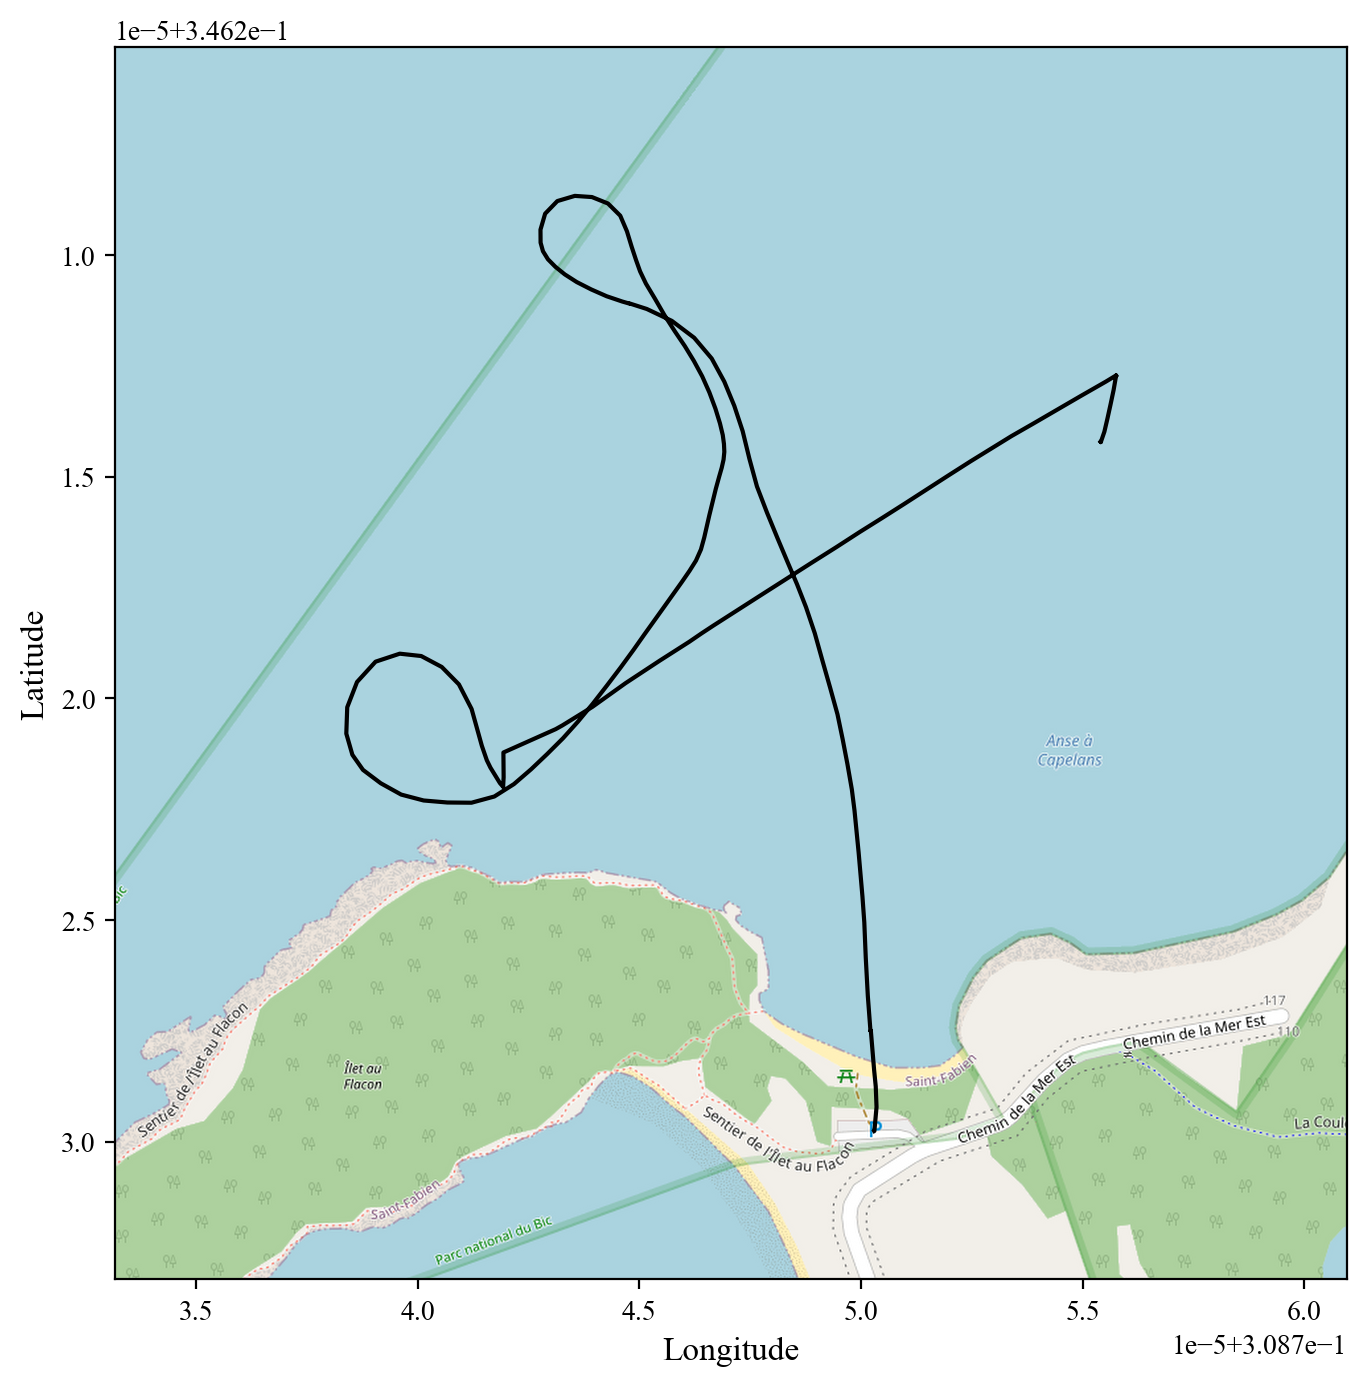

In [25]:
import icewave.gps.gps as gps
gps.map_traj(Lons,Lats)
[X,Y] = gps.project(np.mean(Lons),np.mean(Lats))

plt.plot(

In [ ]:
plt.imshow(im)
plt.colorbar()

153.87154764491032


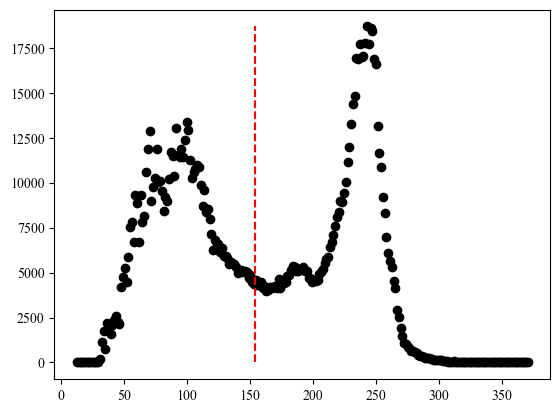

In [125]:
norm = np.linalg.norm(im,axis=2)
[n,x] = np.histogram(np.ndarray.flatten(norm),256)

ind = np.argmin(np.abs(np.cumsum(n)/np.sum(n)-0.5))
print(x[ind])

xc = (x[1:]+x[:-1])/2
plt.plot(xc,n,'ko')
plt.vlines(x[ind],ymin=0,ymax=max(n),color='r',linestyles='--')


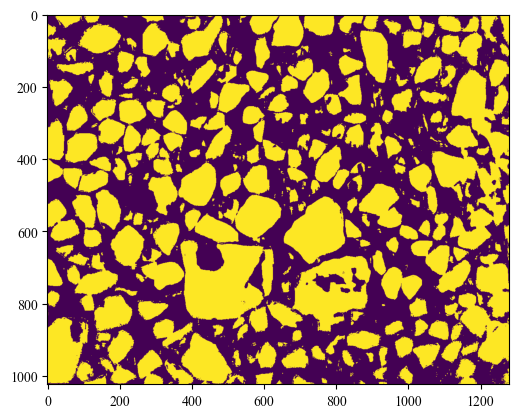

In [127]:
def binarize(im):
    m = {}
    m['im'] = im
    m['bw'] = np.linalg.norm(m['im'],axis=2)
    
    [n,x] = np.histogram(np.ndarray.flatten(m['bw']),256)
    ind = np.argmin(np.abs(np.cumsum(n)/np.sum(n)-0.5)) #cut in half the histogram
    
    m['thres'] = np.floor(x[ind])
    m['binary'] = norm<m['thres']
    return m

m = binarize(im)
plt.imshow(m['binary'])

(1024, 1280)


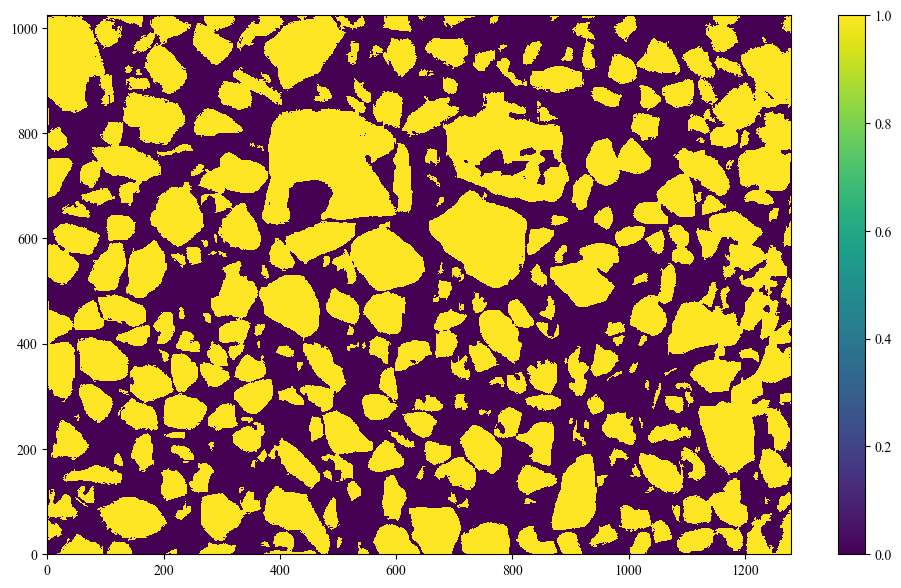

In [129]:
from skimage import measure
import scipy.ndimage as nd

def regionprops(m):
    struct = [[1,1,1],[1,1,1],[1,1,1]]
    labels = nd.label(np.asarray(m['binary']), structure=struct)[0]
    #colormap of the fracture, color codes the time of opening (in rot max ?)
    props = measure.regionprops_table(labels,properties=['area'])#,'perimeter','axis_major_length','axis_minor_length','centroid','eccentricity','intensity_mean','intensity_max','intensity_median','intensity_std'])

    Thres = 50 #remove all areas smaller than 50 pixels
    labnums = np.where(props['area']>=Thres)[0]+1
    #print(labnums)
    [ny,nx] = m['binary'].shape

    bigs_mask = np.asarray([[(labels[i,j] in labnums) for j in range(nx)] for i in range(ny)])

    bigs = m['binary']*bigs_mask
    labels = nd.label(np.asarray(bigs), structure=struct)[0]
    props = measure.regionprops_table(labels, intensity_image=m['bw'],properties=['area','perimeter','axis_major_length','axis_minor_length','centroid','eccentricity','intensity_mean','intensity_max','intensity_median','intensity_std'])

    return props,bigs

props,bigs = regionprops(m)
m['bigs'] = bigs
m['props'] = props

fig,ax = plt.subplots(figsize=(12,7))#,nrows=2,sharex=True)
#Z = m['binary']*m['tmaxs_rot']
sc = ax.pcolormesh(bigs)
plt.colorbar(sc)
#labels
#m['labnums'] = labnums

In [115]:
props.keys()

dict_keys(['area', 'perimeter', 'axis_major_length', 'axis_minor_length', 'centroid-0', 'centroid-1', 'eccentricity', 'intensity_mean', 'intensity_max', 'intensity_median', 'intensity_std'])

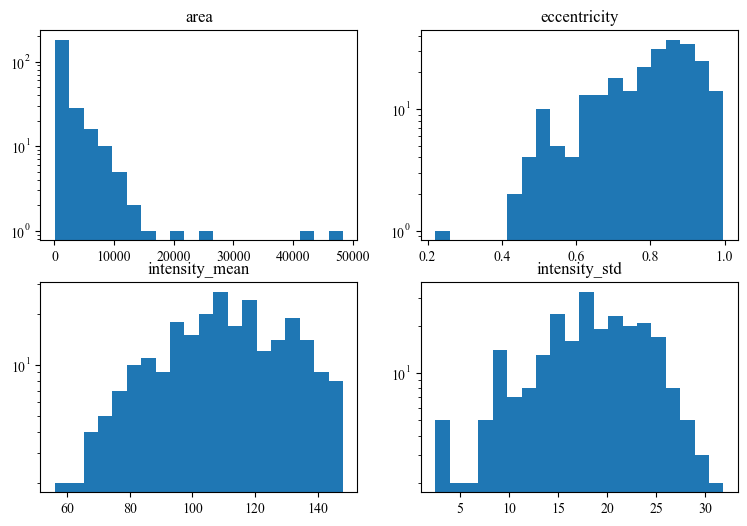

In [116]:
fig,axs = plt.subplots(figsize=(9,6),nrows=2,ncols=2)
axs = np.ndarray.flatten(axs)

keyprops = ['area','eccentricity','intensity_mean','intensity_std']
for (ax,key) in zip(axs,keyprops):
    ax.hist(props[key],20)
    ax.set_yscale('log')
    graphes.legende('','',key,ax=ax)
plt.subplots_adjust(wspace=0.2)

In [226]:
mesure

dict_keys(['im', 'bw', 'thres', 'binary', 'bigs', 'props'])

1280 1024


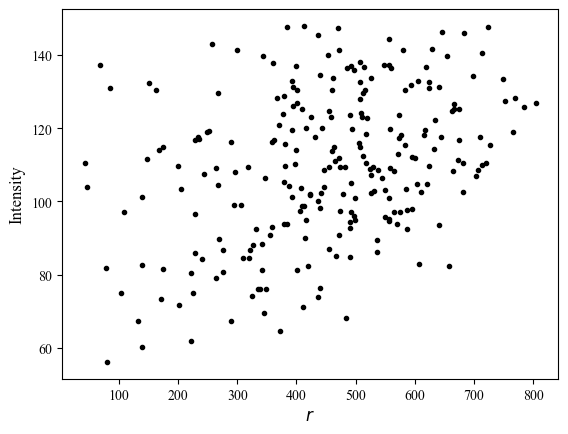

In [120]:
import icewave.tools.maths as maths
print(nx,ny)
[r,theta] = maths.cart2pol(props['centroid-0']-ny/2,props['centroid-1']-nx/2)
#plt.plot(props['centroid-0']-ny/2,props['centroid-1']-nx/2,'ko')

plt.plot(r,props['intensity_mean'],'k.')

figs = graphes.legende('$r$','Intensity','')

/Users/stephane/Documents/BicWin2026/Data_Exemples/IR_0211/DJI_20260212054320_0042_T.JPG
/Users/stephane/Documents/BicWin2026/Data_Exemples/IR_0211/DJI_20260212054323_0043_T.JPG
/Users/stephane/Documents/BicWin2026/Data_Exemples/IR_0211/DJI_20260212054326_0044_T.JPG
/Users/stephane/Documents/BicWin2026/Data_Exemples/IR_0211/DJI_20260212054329_0045_T.JPG
/Users/stephane/Documents/BicWin2026/Data_Exemples/IR_0211/DJI_20260212054332_0046_T.JPG
/Users/stephane/Documents/BicWin2026/Data_Exemples/IR_0211/DJI_20260212054335_0047_T.JPG
/Users/stephane/Documents/BicWin2026/Data_Exemples/IR_0211/DJI_20260212054338_0048_T.JPG
/Users/stephane/Documents/BicWin2026/Data_Exemples/IR_0211/DJI_20260212054341_0049_T.JPG
/Users/stephane/Documents/BicWin2026/Data_Exemples/IR_0211/DJI_20260212054344_0050_T.JPG
/Users/stephane/Documents/BicWin2026/Data_Exemples/IR_0211/DJI_20260212054347_0051_T.JPG
/Users/stephane/Documents/BicWin2026/Data_Exemples/IR_0211/DJI_20260212054350_0052_T.JPG
/Users/stephane/Docum

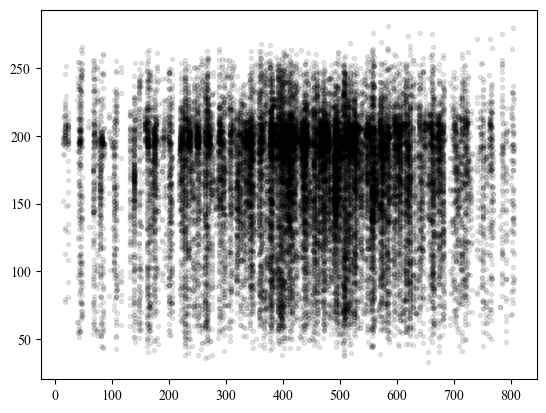

In [227]:
mesures = {}

nums = []
for imagename in filelist:
    nums.append(int(os.path.basename(imagename).split('.')[0].split('_')[-2]))

indices = np.argsort(nums)
filelist = np.asarray(filelist)[indices]

for imagename in filelist[40:172]:
    num = int(os.path.basename(imagename).split('.')[0].split('_')[-2])
    print(imagename)
    im = plt.imread(imagename)
    m = binarize(im)
    [ny,nx] = m['bw'].shape

    props,bigs = regionprops(m)
    m['bigs'] = bigs
    m['props'] = props

    [r,theta] = maths.cart2pol(props['centroid-0']-ny/2,props['centroid-1']-nx/2)
    plt.plot(r,props['intensity_mean'],'k.',alpha=0.1)
    mesures[num] = {}
    mesures[num]['props'] = m['props']
    mesures[num]['thres'] = m['thres']
    mesures[num]['filename'] = imagename
    #mesures[
    #print(m.keys())

In [133]:
m.keys()

dict_keys(['im', 'bw', 'thres', 'binary'])

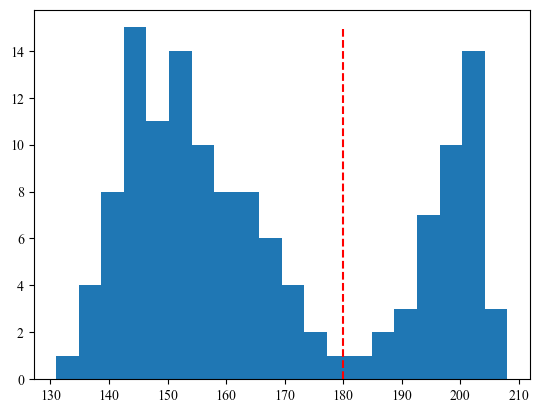

In [204]:
thresholds = [mesures[key]['thres'] for key in mesures.keys()]

[n,x,a] = plt.hist(thresholds,20)
cut = 180

plt.vlines(cut,ymin=0,ymax = max(n),linestyles='--',color='r')

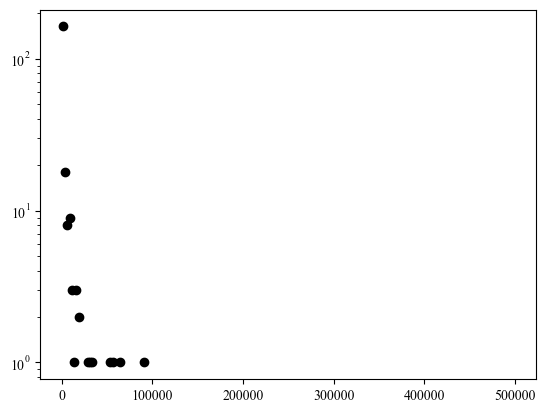

In [205]:

[n,x] = np.histogram(mesures[50]['props']['area'],200,range=[0,500000])
xc = (x[1:]+x[:-1])/2
plt.plot(xc,n,'ko')
plt.yscale('log')

In [206]:
axs = np.ndarray.flatten(axs)
keyprops = ['area','eccentricity','intensity_mean','intensity_std']

res = {}
for k in keyprops:
    res[k]=[]

for key in mesures.keys():
    if mesures[key]['thres']>cut:
        continue
    for k in keyprops:
        res[k]=res[k]+list(mesures[key]['props'][k])

for k in keyprops:
    res[k] = np.asarray(res[k])
print(res.keys())

dict_keys(['area', 'eccentricity', 'intensity_mean', 'intensity_std'])


In [174]:
res['area']

array([1930.,  872.,  129., ...,   96.,  101.,  120.], shape=(26842,))

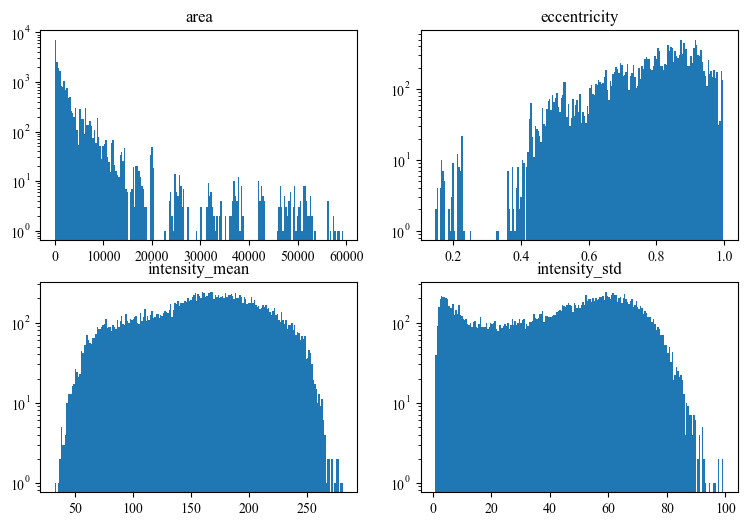

In [207]:
fig,axs = plt.subplots(figsize=(9,6),nrows=2,ncols=2)

axs = np.ndarray.flatten(axs)
for (ax,key) in zip(axs,keyprops):
    ax.hist(res[key],200)
    ax.set_yscale('log')
    graphes.legende('','',key,ax=ax)
plt.subplots_adjust(wspace=0.2)

{1: {'fignum': 'intensity_mean_vs_area',
  'data': {'xdata_0': array([1766.,  825.,  116., ...,   93.,   80.,  117.], shape=(22625,)),
   'ydata_0': array([133.92803642, 193.37252281, 202.40369711, ..., 224.22082288,
          246.84624836, 131.41627441], shape=(22625,))}}}

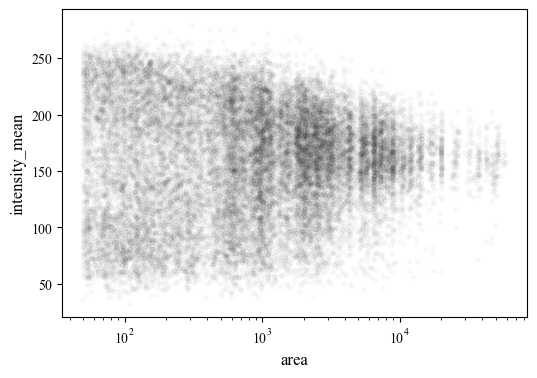

In [208]:
fig,ax = plt.subplots(figsize=(6,4))#,nrows=2,ncols=2)

keyx = 'area'
keyy = 'intensity_mean'

ax.plot(res[keyx],res[keyy],'.',color='k',alpha=0.02)

ax.set_xscale('log')

graphes.legende(keyx,keyy,'')

{1: {'fignum': 'eccentricity_vs_area',
  'data': {'xdata_0': array([1766.,  825.,  116., ...,   93.,   80.,  117.], shape=(22625,)),
   'ydata_0': array([0.87267708, 0.79902978, 0.86103066, ..., 0.83875218, 0.74898778,
          0.96587904], shape=(22625,))}}}

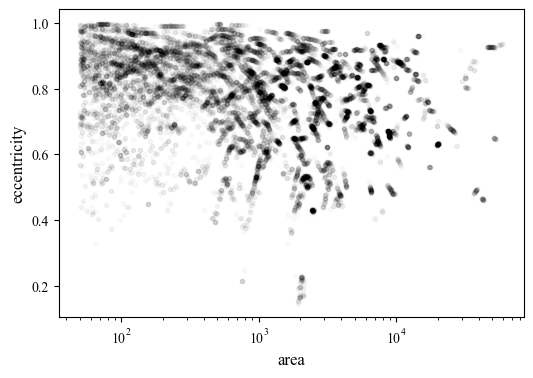

In [209]:
fig,ax = plt.subplots(figsize=(6,4))#,nrows=2,ncols=2)

keyx = 'area'
keyy = 'eccentricity'

ax.plot(res[keyx],res[keyy],'.',color='k',alpha=0.02)

ax.set_xscale('log')

graphes.legende(keyx,keyy,'')

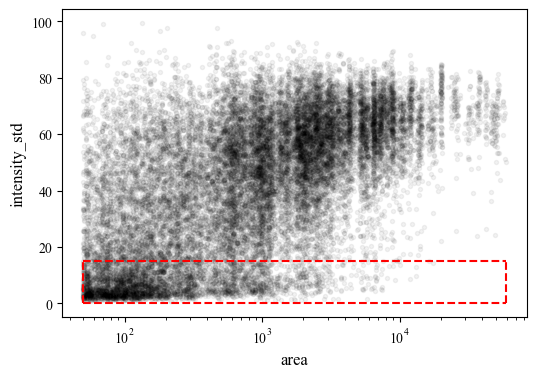

In [224]:
fig,ax = plt.subplots(figsize=(6,4))#,nrows=2,ncols=2)

keyx = 'area'
keyy = 'intensity_std'

I0 = 15
amin = np.min(res[keyx])
amax = np.max(res[keyx])

indices = res[keyy]<I0
ax.plot(res[keyx],res[keyy],'.',color='k',alpha=0.05)

ax.vlines(amin,ymin=0,ymax=I0,linestyles='--',color='r')
ax.vlines(amax,ymin=0,ymax=I0,linestyles='--',color='r')
ax.hlines(0,xmin=amin,xmax=amax,linestyles='--',color='r')
ax.hlines(I0,xmin=amin,xmax=amax,linestyles='--',color='r')

ax.set_xscale('log')

figs = graphes.legende(keyx,keyy,'')
#graphes.save_figs(figs,savedir=savefolder,prefix='0211_selection_on_std_',overwrite=True)

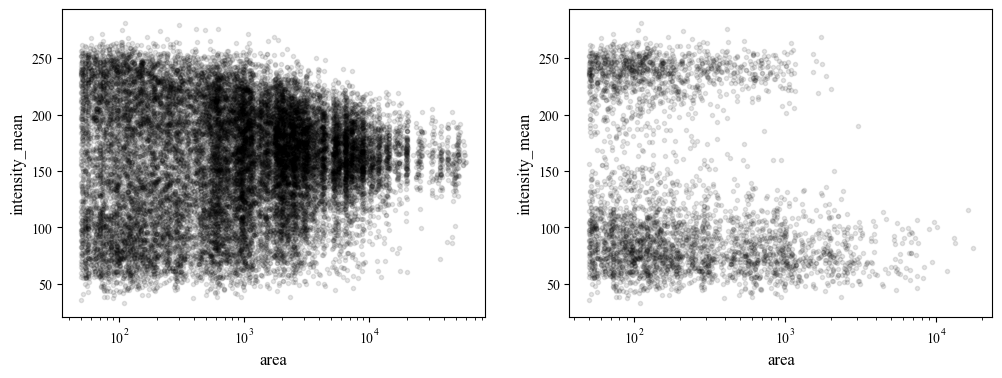

In [219]:
fig,axs = plt.subplots(figsize=(12,4),ncols=2)

keyx = 'area'
keyy = 'intensity_mean'

axs[0].plot(res[keyx],res[keyy],'.',color='k',alpha=0.1)
axs[0].set_xscale('log')

axs[1].plot(res[keyx][indices],res[keyy][indices],'.',color='k',alpha=0.1)
axs[1].set_xscale('log')
figs = graphes.legende(keyx,keyy,'',ax=axs[0])
figs = graphes.legende(keyx,keyy,'',ax=axs[1])
graphes.save_figs(figs,savedir=savefolder,prefix='0211_fragments_props_',overwrite=True)

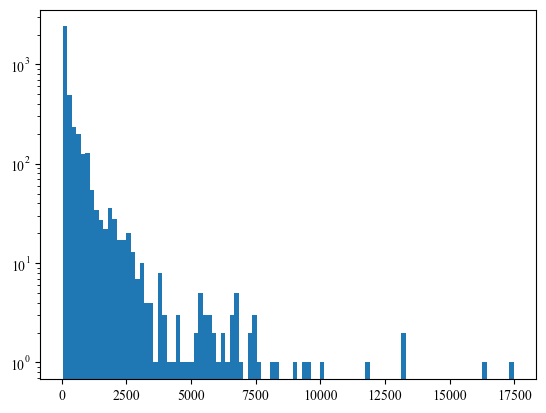

In [221]:
[n,x,a] = plt.hist(res['area'][indices],100)
plt.yscale('log')

In [229]:
mesures.keys()

dict_keys([42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142, 143, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155, 156, 157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168, 169, 170, 171, 172, 173, 174, 175])

In [243]:
import icewave.tools.rw_data as rw

filename = savefolder + 'regionprops_images_0211_exemple.h5'
rw.save_dict_to_h5(mesures,filename)

TypeError: A name should be string or bytes, not <class 'int'>

In [238]:
print(mesures.keys())
print(mesures[42].keys())
print(mesures[42]['props'].keys())

dict_keys([42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142, 143, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155, 156, 157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168, 169, 170, 171, 172, 173, 174, 175])
dict_keys(['props', 'thres', 'filename'])
dict_keys(['area', 'perimeter', 'axis_major_length', 'axis_minor_length', 'centroid-0', 'centroid-1', 'eccentricity', 'intensity_mean', 'intensity_max', 'intensity_median', 'intensity_std'])
